,Metode,Total Unit Overstock,Total Unit Stockout,Total Biaya Simpan (Rp),Potensi Lost Sales (Rp),Total Kerugian (Rp),Service Level (%)
0,Metode Lama (Baseline),967003,5290,2.901009e+09,79350000.0,2.980359e+09,97.34
1,Model LightGBM,610565,7483,1.831695e+09,112245000.0,1.943940e+09,95.89


Estimasi penghematan bersih selama 3 bulan: Rp 1,036,419,000 (34.77%)


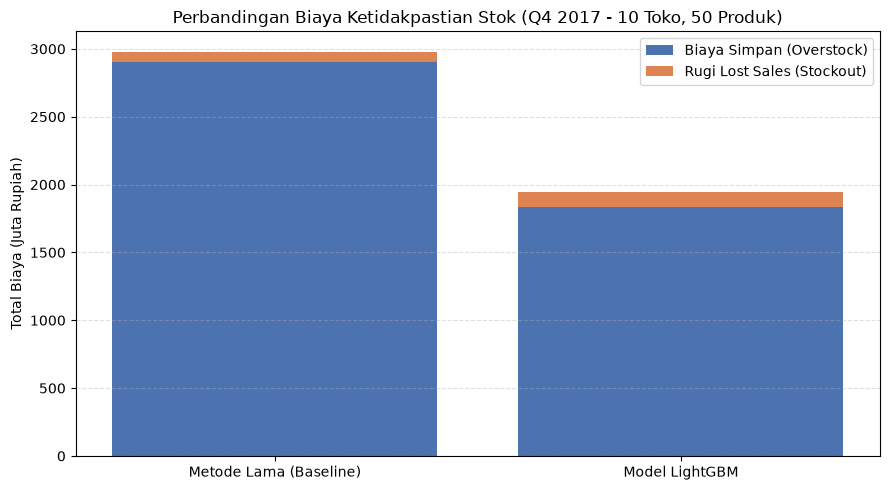

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load hasil prediksi pada data validasi (Oktober - Desember 2017)
val = pd.read_parquet('../data/processed/val_predictions.parquet')

import gc # Garbage collector untuk membersihkan memori
# 1. Load HANYA kolom yang dibutuhkan untuk simulasi
kolom_dibutuhkan = ['date', 'store', 'item', 'sales', 'sales_lag_7', 'pred_lgb']
val = pd.read_parquet('../data/processed/val_predictions.parquet', columns=kolom_dibutuhkan)

# 2. Perkecil ukuran tipe data (Downcasting)
val['store'] = val['store'].astype('int16')
val['item'] = val['item'].astype('int16')
val['sales'] = val['sales'].astype('float32')
val['sales_lag_7'] = val['sales_lag_7'].astype('float32')
val['pred_lgb'] = val['pred_lgb'].astype('float32')

gc.collect() # Paksa Python membuang sampah memori yang tidak terpakai


# 2. Asumsi parameter bisnis (dalam rupiah)
# Misal, ritel kebutuhan harian dengan margin Rp 15.000/unit dan biaya simpan Rp 3000/unit
LOST_SALES_COST =  15000 # Kerugian profit jika stok (Under-forecast)
HOLDING_COST = 3000 # Biaya simpan jika stok berlebih (Over-forecast)
Z_SCORE = 1.65 # Target service level 95%

def hitung_biaya_inventaris(df_eval, col_prediksi, nama_metode): 
    df_sim = df_eval.copy()

    # 3. Hitung error historis untuk menentukan Safety Stock per item & store
    df_sim['error'] = df_sim['sales'] - df_sim[col_prediksi]
    std_error = df_sim.groupby(['store', 'item'])['error'].transform('std').fillna(0)

    # 4. Hitung total stok yang disiapkan (Prediksi + Safety Stock)
    df_sim['safety_stock'] = np.ceil(Z_SCORE * std_error)
    df_sim['stok_disiapkan'] = np.maximum(0, np.round(df_sim[col_prediksi]) + df_sim['safety_stock'])

    # 5. Hitung selisih antara stok disiapkan dan penjualan aktual
    selisih = df_sim['stok_disiapkan'] - df_sim['sales']

    # 6. Jika selisih > 0 berarti overstock; jika selisih < 0 berarti stockout
    df_sim['unit_overstock'] = np.where(selisih > 0, selisih, 0)
    df_sim['unit_stockout'] = np.where(selisih < 0, np.abs(selisih), 0)

    # 7. Konversi ke Rupiah
    total_holding_cost = (df_sim['unit_overstock'] * HOLDING_COST).sum()
    total_lost_sales_cost = (df_sim['unit_stockout'] * LOST_SALES_COST).sum()
    total_kerugian = total_holding_cost + total_lost_sales_cost

    # Menghitung persentase hari di mana toko tidak mengalami stockout (Actual service level)
    service_level = (df_sim['unit_stockout'] == 0).mean() * 100

    return {
        'Metode': nama_metode,
        'Total Unit Overstock': int(df_sim['unit_overstock'].sum()),
        'Total Unit Stockout': int(df_sim['unit_stockout'].sum()),
        'Total Biaya Simpan (Rp)': total_holding_cost,
        'Potensi Lost Sales (Rp)': total_lost_sales_cost,
        'Total Kerugian (Rp)': total_kerugian,
        'Service Level (%)': round(service_level, 2)
    }


# 3. Benchmark metode Lama (Baseline minggu lalu) vs Model LightGBM
hasil_baseline = hitung_biaya_inventaris(val, 'sales_lag_7', 'Metode Lama (Baseline)')
hasil_lgb = hitung_biaya_inventaris(val, 'pred_lgb', 'Model LightGBM')

df_perbandingan = pd.DataFrame([hasil_baseline, hasil_lgb])
display(df_perbandingan)


# 4. Visualisasi penghematan bersih selama 3 bulan (Oktober - Desember 2017)
penghematan = hasil_baseline['Total Kerugian (Rp)'] - hasil_lgb['Total Kerugian (Rp)']
persen_hemat = (penghematan / hasil_baseline['Total Kerugian (Rp)']) * 100

print(f"Estimasi penghematan bersih selama 3 bulan: Rp {penghematan:,.0f} ({persen_hemat:.2f}%)")


# 5. Visualisasi perbandingan biaya (dalam juta rupiah)
fig, ax = plt.subplots(figsize=(9, 5))

metode = df_perbandingan['Metode']
biaya_simpan = df_perbandingan['Total Biaya Simpan (Rp)'] / 1e6
biaya_lost = df_perbandingan['Potensi Lost Sales (Rp)'] / 1e6

ax.bar(metode, biaya_simpan, label='Biaya Simpan (Overstock)', color='#4C72B0')
ax.bar(metode, biaya_lost, bottom=biaya_simpan, label='Rugi Lost Sales (Stockout)', color='#DD8452')

ax.set_ylabel('Total Biaya (Juta Rupiah)')
ax.set_title('Perbandingan Biaya Ketidakpastian Stok (Q4 2017 - 10 Toko, 50 Produk)')
ax.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()